# Loan Default Prediction
**NTUC Associate Data Analyst Capstone – Finance track**
Reshma

In this project I try to predict whether a bank customer will **default** on a loan (not pay it back), using information the bank already has *before* it approves the loan.

The data is the PKDD'99 Czech bank dataset (1993–1998). It comes as 8 separate CSV files, so a big part of the work is cleaning them and joining them into one table.

**What's in this notebook**
1. Problem statement and research objectives
2. Loading the data
3. Data cleaning
4. Joining the 8 tables
5. Creating features
6. Exploring the data
7. Building and comparing models
8. Tuning and final test
9. What drives default?
10. Sanity check
11. Deployment
12. Web app demo
13. Scalability and adaptability
14. Monitoring
15. Conclusion and recommendations

To run it: keep the 8 CSV files in the same folder as this notebook and click **Run all** (takes 1–2 minutes).

## 1. Problem statement and research objectives

**Problem:** Some borrowers don't repay their loans, and the bank loses money. In this bank about 1 in 9 loans went bad. If the bank could spot risky applicants before approving the loan, it could reduce these losses.

**Research objectives**
1. Clean the 8 tables and combine them into one reliable table (one row per loan).
2. Check whether account behaviour before the loan (balances, income, overdrafts) is linked to default.
3. Check whether the loan terms (amount, length, monthly payment) are linked to default.
4. Check whether customer and regional factors (age, card, district) matter.
5. Build and compare models that predict default, using the **F1 score** as the main measure (pass mark 0.50).
6. Find the main risk drivers and turn them into recommendations for the bank.

This is a **classification** problem: each loan is either "default" or "good", and the model learns from past loans where we already know the answer.

### Connecting to the data folder
On Google Colab the notebook starts in an empty folder, so I first connect Google Drive and move into the folder with the CSV files. (On my own computer this cell does nothing.)

In [ ]:
import os, glob
try:
    from google.colab import drive
    drive.mount("/content/drive")
    folder = "/content/drive/MyDrive/Capstone"   # change this if your folder has a different name
    if not os.path.exists(os.path.join(folder, "Loan.csv")):
        # not there? look for Loan.csv anywhere in My Drive
        found = glob.glob("/content/drive/MyDrive/**/Loan.csv", recursive=True)
        folder = os.path.dirname(found[0]) if found else folder
    os.chdir(folder)
except ImportError:
    pass   # not on Colab: the notebook is already in the project folder

if os.path.exists("data/Loan.csv"):
    os.chdir("data")   # repository layout: the CSV files are in the data folder
print("Working folder:", os.getcwd())
print("Loan.csv found:", os.path.exists("Loan.csv"))

### Importing libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42   # so I get the same results every time I run it
GOOD, BAD = "#2a78d6", "#eb6834"   # blue = good loans, orange = defaults in all my charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
pd.set_option("display.max_columns", 60)

## 2. Loading the data

The 8 files and what one row means in each:

| File | One row is | Links to |
|---|---|---|
| Loan | a loan (682) – has the **status**, which is what I want to predict | Account |
| Account | a bank account (4,500) | District |
| Disp | a person's role on an account (owner or user) | Client, Account |
| Client | a customer (5,369) | District |
| Card | a payment card (892) | Disp |
| Transaction | one transaction (about 1.06 million) | Account |
| Order | a standing payment order (6,471) | Account |
| District | a region with economic data (77) | Account, Client |

In [3]:
account  = pd.read_csv("Account.csv")
card     = pd.read_csv("Card.csv")
client   = pd.read_csv("Client.csv")
disp     = pd.read_csv("Disp.csv")
district = pd.read_csv("District.csv")
loan     = pd.read_csv("Loan.csv")
order    = pd.read_csv("Order.csv")
trans_file = "Transaction.csv" if os.path.exists("Transaction.csv") else "Transaction.csv.zip"   # zipped copy on GitHub
trans    = pd.read_csv(trans_file, low_memory=False)   # this one is big, takes a few seconds

tables = {"Account": account, "Card": card, "Client": client, "Disp": disp,
          "District": district, "Loan": loan, "Order": order, "Transaction": trans}

# quick overview of every table
for name, t in tables.items():
    print(f"{name:12} rows: {len(t):>9,}   columns: {t.shape[1]:>2}   missing cells: {t.isna().sum().sum():>7,}   duplicate rows: {t.duplicated().sum()}")

Account      rows:     4,500   columns:  4   missing cells:       0   duplicate rows: 0
Card         rows:       892   columns:  4   missing cells:       0   duplicate rows: 0
Client       rows:     5,369   columns:  4   missing cells:       0   duplicate rows: 0
Disp         rows:     5,369   columns:  4   missing cells:       0   duplicate rows: 0
District     rows:        77   columns: 16   missing cells:       2   duplicate rows: 0
Loan         rows:       682   columns:  7   missing cells:       0   duplicate rows: 0
Order        rows:     6,471   columns:  6   missing cells:   1,379   duplicate rows: 0


Transaction  rows: 1,056,320   columns: 10   missing cells: 2,208,738   duplicate rows: 0


In [4]:
loan.head()

,loan_id,account_id,date,amount,duration,payments,status
0,4959,2,1994-01-05,80952,24,3373.0,A
1,4961,19,1996-04-29,30276,12,2523.0,B
2,4962,25,1997-12-08,30276,12,2523.0,A
3,4967,37,1998-10-14,318480,60,5308.0,D
4,4968,38,1998-04-19,110736,48,2307.0,C


### The target: loan status

The `status` column has four codes (from the data dictionary):

| Code | Meaning | My label |
|---|---|---|
| A | Finished, no problems | Good |
| B | Finished, loan **not paid** | Default |
| C | Still running, OK so far | Good |
| D | Still running, client **in debt** | Default |

So I create a new column `default` = 1 if the status is B or D, otherwise 0.

status
A    203
B     31
C    403
D     45
Name: count, dtype: int64

Default rate: 11.1% (76 out of 682 loans)


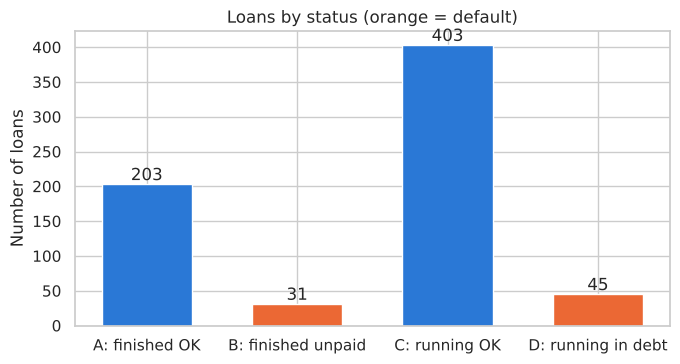

In [5]:
loan["default"] = loan["status"].isin(["B", "D"]).astype(int)

status_counts = loan["status"].value_counts().sort_index()
print(status_counts)
print(f"\nDefault rate: {loan['default'].mean():.1%} ({loan['default'].sum()} out of {len(loan)} loans)")

colors = [GOOD if s in "AC" else BAD for s in status_counts.index]
plt.figure(figsize=(7, 3.8))
plt.bar(["A: finished OK", "B: finished unpaid", "C: running OK", "D: running in debt"], status_counts.values, color=colors, width=0.6)
for i, v in enumerate(status_counts.values):
    plt.text(i, v + 6, v, ha="center")
plt.title("Loans by status (orange = default)")
plt.ylabel("Number of loans")
plt.tight_layout()
plt.show()

Only about 11% of loans defaulted. This is important: a model that just says "good" for everyone would already be 89% accurate but would never catch a single defaulter. That's why I won't use accuracy as my main measure. I'll look at the **confusion matrix** and use **recall** (defaulters caught), **precision** (flags that were right) and the **F1 score**, which balances the two.

## 3. Data cleaning

While looking through the tables I found a few problems. I fix them one by one below and keep a small log of what I changed.

In [6]:
cleaning_log = []

# 1. Dates are stored as text, convert them to real dates
account["date"] = pd.to_datetime(account["date"])
card["issued"] = pd.to_datetime(card["issued"])
client["birth_date"] = pd.to_datetime(client["birth_date"])
loan["date"] = pd.to_datetime(loan["date"])
trans["date"] = pd.to_datetime(trans["date"])
cleaning_log.append(["Account, Card, Client, Loan, Transaction", "Dates stored as text", "Converted to dates",
                     len(account) + len(card) + len(client) + len(loan) + len(trans)])

# 2. Category codes are in Czech, translate them to English
account["frequency"] = account["frequency"].map({"POPLATEK MESICNE": "monthly",
                                                 "POPLATEK TYDNE": "weekly",
                                                 "POPLATEK PO OBRATU": "after transaction"})
n_vyber = (trans["type"] == "VYBER").sum()
trans["type"] = trans["type"].map({"PRIJEM": "credit", "VYDAJ": "debit", "VYBER": "debit"})
trans["operation"] = trans["operation"].map({"VYBER": "cash withdrawal", "PREVOD NA UCET": "transfer out",
                                             "VKLAD": "cash deposit", "PREVOD Z UCTU": "transfer in",
                                             "VYBER KARTOU": "card withdrawal"})
cleaning_log.append(["Account, Transaction, Order", "Category codes in Czech (e.g. PRIJEM, SIPO)", "Translated to English", len(account) + len(trans)])
cleaning_log.append(["Transaction", "'VYBER' used as an extra type for cash withdrawals", "Merged into 'debit'", n_vyber])

# 3. Purpose codes (k_symbol): some are blank spaces, some are empty
purpose = {"UROK": "interest", "SLUZBY": "statement fee", "SIPO": "household", "DUCHOD": "pension",
           "POJISTNE": "insurance", "UVER": "loan payment", "SANKC. UROK": "penalty interest", "LEASING": "leasing"}
n_blank = (trans["k_symbol"].astype("string").str.strip() == "").sum()
n_empty = trans["k_symbol"].isna().sum()
trans["k_symbol"] = trans["k_symbol"].astype("string").str.strip().replace("", pd.NA).map(purpose).fillna("unknown")
cleaning_log.append(["Transaction", "Purpose code has blanks and empty values", "Both set to 'unknown'", n_blank + n_empty])

n_order_missing = order["k_symbol"].isna().sum()
order["k_symbol"] = order["k_symbol"].map(purpose).fillna("other")
cleaning_log.append(["Order", "Missing payment purpose", "Labelled 'other'", n_order_missing])

# 4. One district is missing its 1995 unemployment and crime numbers
missing_district = district[district["A12"].isna() | district["A15"].isna()]["A2"].tolist()
district["A12"] = district["A12"].fillna(district["A13"])   # use the 1996 value instead
district["A15"] = district["A15"].fillna(district["A16"])
cleaning_log.append(["District", f"1995 unemployment and crime missing for {missing_district}", "Filled with the 1996 values", len(missing_district)])

# 5. Transaction amounts are always positive, the direction is in 'type'
trans["signed_amount"] = np.where(trans["type"] == "credit", trans["amount"], -trans["amount"])
cleaning_log.append(["Transaction", "Amounts always positive", "Added signed_amount (+ money in, - money out)", len(trans)])

# 6. Negative balances = overdrafts. I keep them because they are real behaviour
cleaning_log.append(["Transaction", "Negative balances (overdrafts)", "Kept, used later as a risk signal", (trans["balance"] < 0).sum()])

# 7. District columns are called A2, A3 ... give them proper names (from the data dictionary)
district = district.rename(columns={"A2": "district_name", "A3": "region", "A4": "inhabitants", "A10": "urban_ratio",
                                    "A11": "avg_salary", "A12": "unemployment_95", "A13": "unemployment_96",
                                    "A14": "entrepreneurs_per_1000", "A15": "crimes_95", "A16": "crimes_96"})
cleaning_log.append(["District", "Columns named A2 to A16", "Renamed using the data dictionary", len(district)])

cleaning_log = pd.DataFrame(cleaning_log, columns=["table", "issue", "action", "rows_affected"])
cleaning_log

,table,issue,action,rows_affected
0,"Account, Card, Client, Loan, Transaction",Dates stored as text,Converted to dates,1067763
1,"Account, Transaction, Order","Category codes in Czech (e.g. PRIJEM, SIPO)",Translated to English,1060820
2,Transaction,'VYBER' used as an extra type for cash withdra...,Merged into 'debit',16666
3,Transaction,Purpose code has blanks and empty values,Both set to 'unknown',535314
4,Order,Missing payment purpose,Labelled 'other',1379
5,District,1995 unemployment and crime missing for ['Jese...,Filled with the 1996 values,1
6,Transaction,Amounts always positive,"Added signed_amount (+ money in, - money out)",1056320
7,Transaction,Negative balances (overdrafts),"Kept, used later as a risk signal",2999
8,District,Columns named A2 to A16,Renamed using the data dictionary,77


### Checking the data before joining

Before I join the tables I want to be sure the IDs match up properly, otherwise I could lose or duplicate loans.

In [7]:
owners = disp[disp["type"] == "OWNER"]
loan_vs_account = loan.merge(account, on="account_id", suffixes=("", "_account"))

checks = pd.DataFrame({
    "check": [
        "IDs are unique in every table",
        "Every loan's account exists",
        "Only one loan per account",
        "Every account has exactly one owner",
        "Every district ID exists in the District table",
        "Loan amount = months x monthly payment",
        "Loan date is after the account was opened",
        "No duplicate rows in any table",
    ],
    "result": [
        account.account_id.is_unique and loan.loan_id.is_unique and client.client_id.is_unique
            and card.card_id.is_unique and disp.disp_id.is_unique and trans.trans_id.is_unique,
        loan.account_id.isin(account.account_id).all(),
        loan.account_id.is_unique,
        owners.account_id.is_unique and owners.account_id.nunique() == len(account),
        account.district_id.isin(district.district_id).all() and client.district_id.isin(district.district_id).all(),
        (abs(loan.amount - loan.duration * loan.payments) <= 1).all(),
        (loan_vs_account["date"] >= loan_vs_account["date_account"]).all(),
        all(t.duplicated().sum() == 0 for t in tables.values()),
    ],
})
checks

,check,result
0,IDs are unique in every table,True
1,Every loan's account exists,True
2,Only one loan per account,True
3,Every account has exactly one owner,True
4,Every district ID exists in the District table,True
5,Loan amount = months x monthly payment,True
6,Loan date is after the account was opened,True
7,No duplicate rows in any table,True


Everything passes, so the tables are safe to join.

## 4. Joining the 8 tables

The answer (default or not) is in the Loan table, but the useful information is spread over the other tables. I start from the 682 loans and add the other tables one at a time, following the relationship diagram:

- Loan → Account → District
- Account → Disp (owner) → Client
- Disp → Card
- Account → Transactions (summarised, see below)

I use **left joins** so no loan is dropped, and I print the number of rows after each join to make sure it stays at 682.

In [8]:
df = loan.rename(columns={"date": "loan_date"})
print("Loans:", df.shape)

df = df.merge(account.rename(columns={"date": "account_open_date", "district_id": "account_district_id"}),
              on="account_id", how="left", validate="one_to_one")
print("+ Account:", df.shape)

owner = disp[disp["type"] == "OWNER"][["account_id", "client_id", "disp_id"]]
df = df.merge(owner, on="account_id", how="left", validate="one_to_one")
print("+ Disp (owner):", df.shape)

df = df.merge(client.rename(columns={"district_id": "client_district_id"}), on="client_id", how="left", validate="many_to_one")
print("+ Client:", df.shape)

# how many people can use each account (1 = owner only, 2 = owner + another user)
users = disp.groupby("account_id").size().rename("n_account_users").reset_index()
df = df.merge(users, on="account_id", how="left", validate="one_to_one")
print("+ Users per account:", df.shape)

district_cols = ["district_id", "district_name", "region", "inhabitants", "urban_ratio", "avg_salary",
                 "unemployment_96", "entrepreneurs_per_1000", "crimes_96"]
df = df.merge(district[district_cols].rename(columns={"district_id": "account_district_id"}),
              on="account_district_id", how="left", validate="many_to_one")
print("+ District:", df.shape)

# cards: only count a card if it was issued BEFORE the loan
cards = card.merge(disp[["disp_id", "account_id"]], on="disp_id").merge(df[["account_id", "loan_date"]], on="account_id")
cards = cards[cards["issued"] < cards["loan_date"]]
card_type = cards.sort_values("issued").groupby("account_id")["type"].last().rename("card_type").reset_index()
df = df.merge(card_type, on="account_id", how="left", validate="one_to_one")
df["card_type"] = df["card_type"].fillna("none")
print("+ Card (issued before the loan):", df.shape)

Loans: (682, 8)
+ Account: (682, 11)
+ Disp (owner): (682, 13)
+ Client: (682, 16)
+ Users per account: (682, 17)
+ District: (682, 25)
+ Card (issued before the loan): (682, 26)


### Summarising the transactions

There are over a million transactions, so I can't join them directly. Instead I summarise each account's history into a few numbers (average balance, lowest balance, how often it went negative, etc.).

**Important:** I only use transactions from **before** the loan date. Transactions after the loan include the loan repayments themselves, which would basically give the model the answer. This mistake is called **data leakage**, and it makes a model look great in testing but useless in real life.

In [9]:
tr = trans.merge(df[["account_id", "loan_date"]], on="account_id", how="inner")
before_loan = tr["date"] < tr["loan_date"]
print(f"Transactions on loan accounts: {len(tr):,}")
print(f"Used (before the loan):        {before_loan.sum():,}")
print(f"Left out (on/after the loan):  {(~before_loan).sum():,}")
tr = tr[before_loan].copy()

tr["is_negative"] = tr["balance"] < 0
tr["is_penalty"] = tr["k_symbol"] == "penalty interest"
tr["money_in"] = tr["signed_amount"].clip(lower=0)
tr["money_out"] = (-tr["signed_amount"]).clip(lower=0)

g = tr.sort_values("date").groupby("account_id")
behaviour = pd.DataFrame({
    "n_transactions": g.size(),
    "balance_mean": g["balance"].mean(),
    "balance_min": g["balance"].min(),
    "balance_std": g["balance"].std(),
    "balance_last": g["balance"].last(),
    "n_negative_balance": g["is_negative"].sum(),
    "n_penalty_interest": g["is_penalty"].sum(),
    "total_credit": g["money_in"].sum(),
    "total_debit": g["money_out"].sum(),
    "first_trans": g["date"].min(),
}).reset_index()

df = df.merge(behaviour, on="account_id", how="left", validate="one_to_one")
print("\n+ Transaction summary:", df.shape, "-> still one row per loan")

Transactions on loan accounts: 191,556
Used (before the loan):        54,694
Left out (on/after the loan):  136,862

+ Transaction summary: (682, 36) -> still one row per loan


**Why I didn't use the Order table in the model:** the Order table has no dates. I can't tell if an order was set up before or after the loan, so using it could cause leakage. (When I tried including it, the score jumped suspiciously high, which is a warning sign.) I only use it to describe the data.

In [10]:
order.groupby("k_symbol")["amount"].agg(["count", "mean"]).round(0)

,count,mean
k_symbol,,
household,3502,3988.0
insurance,532,1291.0
leasing,341,2227.0
loan payment,717,4233.0
other,1379,2017.0


## 5. Creating features

A "feature" is one piece of information the model uses. Here I create some new ones that I think will be useful. Everything is calculated as of the loan date.

In [11]:
df["client_age"] = (df["loan_date"] - df["birth_date"]).dt.days / 365.25
df["account_age_months"] = (df["loan_date"] - df["account_open_date"]).dt.days / 30.44
months_of_history = ((df["loan_date"] - df["first_trans"]).dt.days / 30.44).clip(lower=1)
df["avg_monthly_income"] = df["total_credit"] / months_of_history
df["avg_monthly_spend"] = df["total_debit"] / months_of_history
df["payment_to_income"] = df["payments"] / df["avg_monthly_income"]          # can they afford it?
df["payment_to_balance"] = df["payments"] / df["balance_mean"].clip(lower=1)   # payment compared with usual balance
df["crime_rate_per_1000"] = df["crimes_96"] / df["inhabitants"] * 1000
df["loan_year"] = df["loan_date"].dt.year

| Feature | Meaning |
|---|---|
| balance_mean / min / last / std | Average, lowest, latest balance before the loan, and how much it jumps around |
| n_negative_balance | Times the account went below zero (overdraft) |
| n_penalty_interest | Times the bank charged penalty interest |
| avg_monthly_income / spend | Money coming in and going out per month |
| payment_to_income | Monthly loan payment ÷ monthly income |
| payment_to_balance | Monthly loan payment ÷ average balance |
| client_age, account_age_months | Age of the customer and of the account on the loan date |
| card_type, n_account_users | Card held before the loan, number of people on the account |
| avg_salary, unemployment_96, crime_rate_per_1000 | Economic situation of the district |

I left out **gender** on purpose (it shouldn't be used for credit decisions), and also the IDs, raw dates and the status itself.

In [12]:
numeric_features = ["amount", "duration", "payments", "client_age", "account_age_months", "n_account_users",
                    "n_transactions", "balance_mean", "balance_min", "balance_std", "balance_last",
                    "n_negative_balance", "n_penalty_interest", "avg_monthly_income", "avg_monthly_spend",
                    "payment_to_income", "payment_to_balance",
                    "avg_salary", "unemployment_96", "entrepreneurs_per_1000", "urban_ratio", "crime_rate_per_1000"]
categorical_features = ["frequency", "card_type"]

print(len(numeric_features), "numeric features +", len(categorical_features), "categorical features")
print("Missing values in these columns:", df[numeric_features + categorical_features].isna().sum().sum())

22 numeric features + 2 categorical features
Missing values in these columns: 0


## 6. Exploring the data

Now I compare defaulters with good borrowers to see what's different about them.

In [13]:
key = ["balance_mean", "balance_min", "balance_last", "n_negative_balance", "payment_to_balance", "avg_monthly_income"]
medians = df.groupby("default")[key].median().T
medians.columns = ["good (median)", "default (median)"]
medians.round(2)

,good (median),default (median)
balance_mean,44112.63,37001.53
balance_min,700.00,389.50
balance_last,39415.50,21958.50
n_negative_balance,0.00,0.00
payment_to_balance,0.09,0.13
avg_monthly_income,25612.81,25316.94


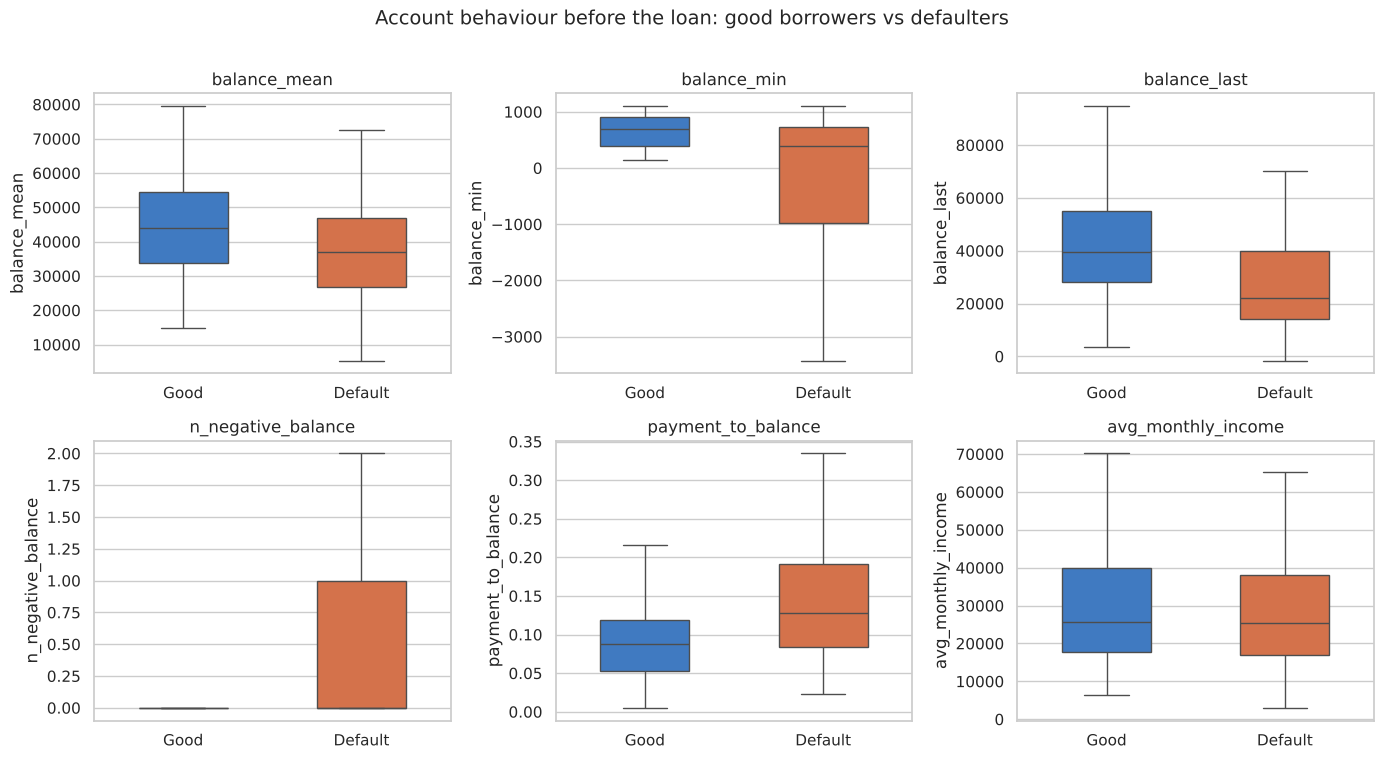

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.ravel(), key):
    sns.boxplot(data=df, x="default", y=col, hue="default", legend=False, ax=ax,
                palette={0: GOOD, 1: BAD}, showfliers=False, width=0.5)
    ax.set_xticklabels(["Good", "Default"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.suptitle("Account behaviour before the loan: good borrowers vs defaulters", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

**What I see:** defaulters had much lower balances, especially the lowest and latest balance before the loan. Their monthly payment was also large compared with what they usually had in the account (higher payment_to_balance).

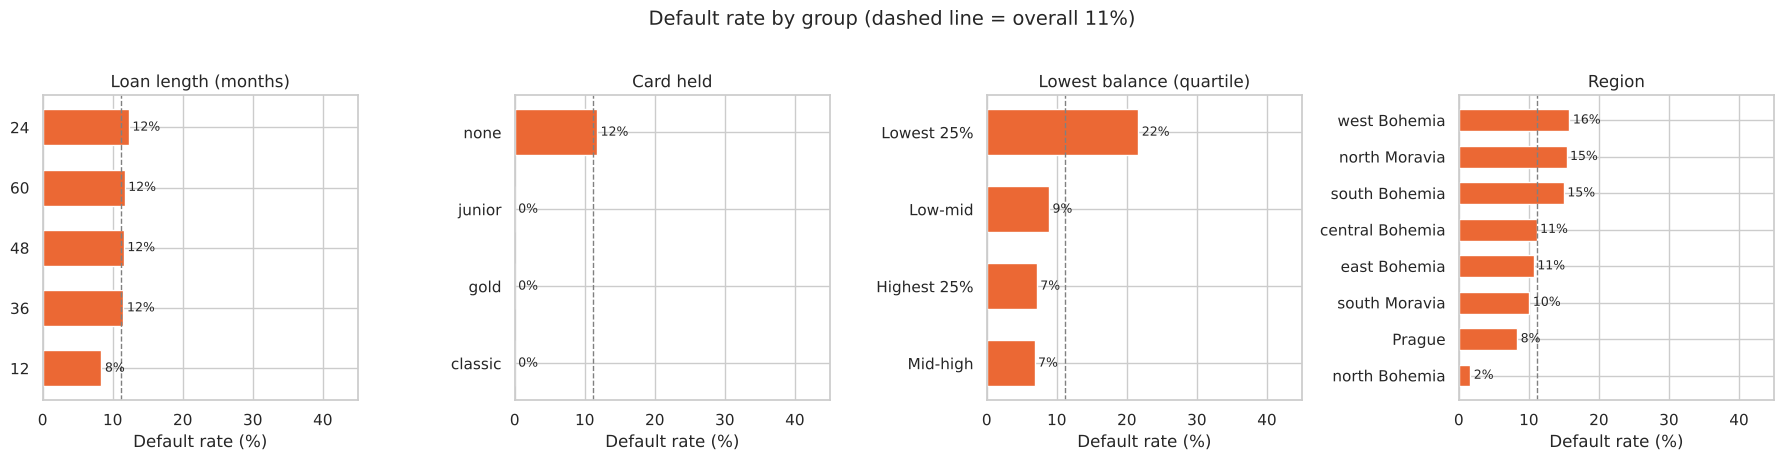

In [15]:
df["balance_band"] = pd.qcut(df["balance_min"], 4, labels=["Lowest 25%", "Low-mid", "Mid-high", "Highest 25%"])
groups = {"duration": "Loan length (months)", "card_type": "Card held",
          "balance_band": "Lowest balance (quartile)", "region": "Region"}
overall = df["default"].mean()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (col, title) in zip(axes, groups.items()):
    rate = df.groupby(col, observed=True)["default"].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values * 100, color=BAD, height=0.6)
    ax.axvline(overall * 100, color="grey", linestyle="--", linewidth=1)
    for i, v in enumerate(rate.values):
        ax.text(v * 100 + 0.5, i, f"{v:.0%}", va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("Default rate (%)")
    ax.set_xlim(0, max(45, rate.max() * 110))
plt.suptitle("Default rate by group (dashed line = overall 11%)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Customers in the lowest balance group defaulted far more often than the rest. Loan length, card and region show smaller differences.

Next, the correlation of each feature with default:

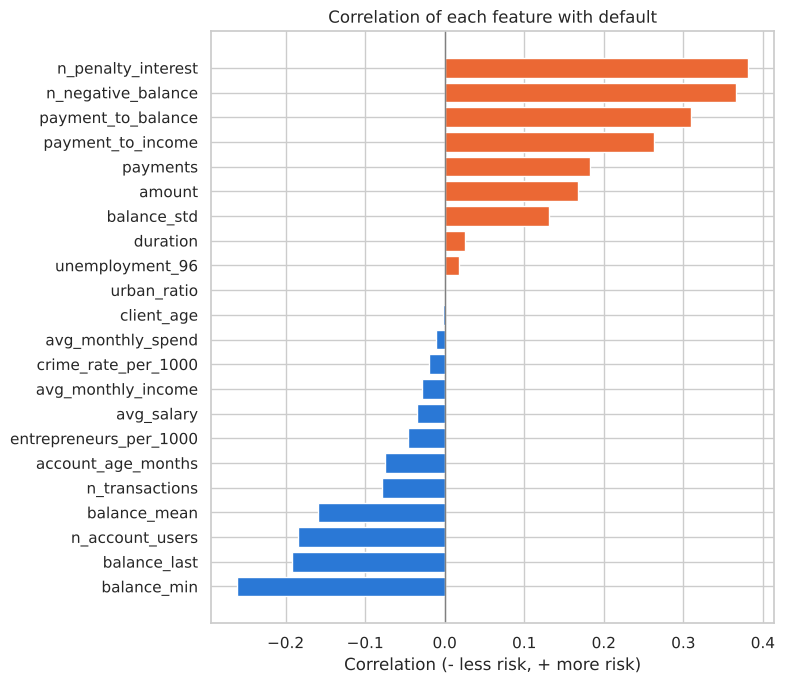

In [16]:
corr = df[numeric_features + ["default"]].corr()["default"].drop("default").sort_values()

plt.figure(figsize=(8, 7))
plt.barh(corr.index, corr.values, color=[BAD if v > 0 else GOOD for v in corr.values])
plt.axvline(0, color="grey", linewidth=1)
plt.title("Correlation of each feature with default")
plt.xlabel("Correlation (- less risk, + more risk)")
plt.tight_layout()
plt.show()

### Statistical tests

To check that these differences are not just chance, I use:
- **Mann-Whitney U** test for number columns (compares defaulters vs good borrowers)
- **Chi-square** test for category columns

If the p-value is below 0.05, the difference is statistically significant.

In [17]:
results = []
for col in numeric_features:
    _, p = stats.mannwhitneyu(df.loc[df["default"] == 1, col], df.loc[df["default"] == 0, col])
    results.append([col, "Mann-Whitney U", p])
for col in categorical_features + ["gender", "region"]:
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(df[col], df["default"]))
    results.append([col, "Chi-square", p])

tests = pd.DataFrame(results, columns=["feature", "test", "p_value"]).sort_values("p_value")
tests["significant (p<0.05)"] = tests["p_value"] < 0.05
print(tests["significant (p<0.05)"].sum(), "out of", len(tests), "features are significantly linked to default")
tests.round(4)

11 out of 26 features are significantly linked to default


,feature,test,p_value,significant (p<0.05)
11,n_negative_balance,Mann-Whitney U,0.0000,True
12,n_penalty_interest,Mann-Whitney U,0.0000,True
16,payment_to_balance,Mann-Whitney U,0.0000,True
10,balance_last,Mann-Whitney U,0.0000,True
8,balance_min,Mann-Whitney U,0.0000,True
5,n_account_users,Mann-Whitney U,0.0000,True
2,payments,Mann-Whitney U,0.0000,True
15,payment_to_income,Mann-Whitney U,0.0000,True
0,amount,Mann-Whitney U,0.0001,True
7,balance_mean,Mann-Whitney U,0.0002,True


## 7. Building and comparing models

**How I measure the models.** I use the scores from the confusion matrix:
- **Accuracy** = all correct predictions ÷ all loans (misleading here, see above)
- **Precision** = defaulters caught ÷ all loans the model flagged ("when it flags, how often is it right?")
- **Recall** = defaulters caught ÷ all real defaulters ("how many bad loans did it stop?")
- **F1 score** = a balance of precision and recall (0 = useless, 1 = perfect)

**My main measure is F1**, because it rewards catching defaulters without flagging too many good customers. The baseline that always says "good" scores 0, so I set my **pass mark at F1 = 0.50**.

### Train / test split
I keep 20% of the loans hidden as a final test. `stratify=y` keeps the same 11% default rate in both parts.

In [18]:
X = df[numeric_features + categorical_features]
y = df["default"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Training loans:", len(X_train), f"(default rate {y_train.mean():.1%})")
print("Test loans:    ", len(X_test), f"(default rate {y_test.mean():.1%})")

# preparation steps: scale the numbers, turn the text categories into 0/1 columns
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

def make_model(estimator):
    # putting the preparation and the model in one pipeline means the preparation only learns from training data
    return Pipeline([("prep", preprocess), ("model", estimator)])

Training loans: 545 (default rate 11.2%)
Test loans:     137 (default rate 10.9%)


### Comparing 5 models with cross-validation

Cross-validation splits the training data into 5 parts and tests the model 5 times, each time on a different part. It's like 5 practice exams, so one lucky split can't fool me.

`class_weight="balanced"` tells the model that defaulters are rare, so missing one should count more.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1"]

models = {
    "Baseline (always 'good')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    scores = cross_validate(make_model(model), X_train, y_train, cv=cv, scoring=scoring)
    rows.append([name] + [scores[f"test_{m}"].mean() for m in scoring])

cv_results = pd.DataFrame(rows, columns=["model"] + scoring).set_index("model").round(3)
cv_results

,accuracy,precision,recall,f1
model,,,,
Baseline (always 'good'),0.888,0.000,0.000,0.000
Logistic Regression,0.811,0.348,0.723,0.464
Decision Tree,0.769,0.277,0.588,0.364
Random Forest,0.906,0.611,0.508,0.541
Gradient Boosting,0.921,0.767,0.409,0.528


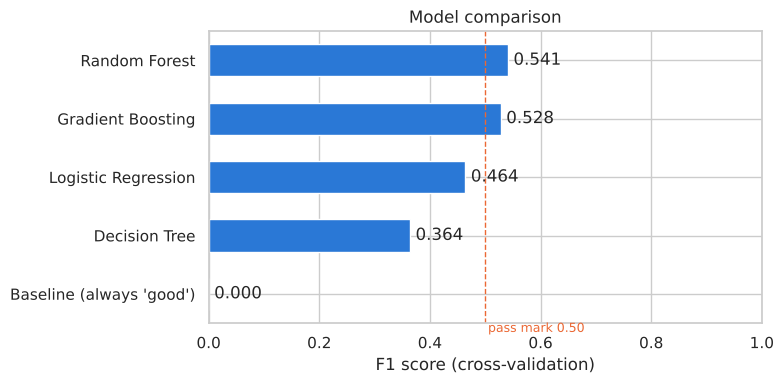

In [20]:
f1 = cv_results["f1"].sort_values()
plt.figure(figsize=(8, 4))
plt.barh(f1.index, f1.values, color=GOOD, height=0.55)
plt.axvline(0.5, color=BAD, linestyle="--", linewidth=1)
plt.text(0.505, -0.65, "pass mark 0.50", fontsize=9, color=BAD)
for i, v in enumerate(f1.values):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.xlim(0, 1.0)
plt.xlabel("F1 score (cross-validation)")
plt.title("Model comparison")
plt.tight_layout()
plt.show()

Random Forest has the best F1 (about 0.54) and Gradient Boosting is close behind (0.53); both pass 0.50. Logistic Regression catches the most defaulters (recall 72%) but also flags many good customers (precision 35%), so its F1 is lower. The baseline scores 0 because it never flags anyone.

Notice that the most *accurate* models are not the ones that catch the most defaulters, which is why accuracy alone is misleading here.

I'll take the Random Forest forward and tune it.

## 8. Tuning and final test

### Tuning the Random Forest
I try 12 random combinations of settings (number of trees, depth, leaf size) and keep the one with the best cross-validated F1 score.

In [21]:
param_options = {
    "model__n_estimators": [150, 250, 400],
    "model__max_depth": [4, 6, 8, None],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": ["sqrt", 0.5],
}
search = RandomizedSearchCV(
    make_model(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions=param_options, n_iter=12, scoring="f1", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)

best_model = search.best_estimator_
print("Best settings:", search.best_params_)
print(f"Best F1 in cross-validation: {search.best_score_:.3f}")

Best settings: {'model__n_estimators': 250, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None}
Best F1 in cross-validation: 0.564


### Final test on the hidden loans
Now the real exam: the 137 loans the model has never seen.

In [22]:
y_proba = best_model.predict_proba(X_test)[:, 1]   # probability of default for each test loan
y_pred = (y_proba >= 0.5).astype(int)
test_f1 = f1_score(y_test, y_pred)
test_scores = {"Accuracy": accuracy_score(y_test, y_pred), "Precision": precision_score(y_test, y_pred),
               "Recall": recall_score(y_test, y_pred), "F1": test_f1}

print(f"Accuracy:  {test_scores['Accuracy']:.3f}   <- all correct / all loans")
print(f"Precision: {test_scores['Precision']:.3f}   <- share of flagged loans that really defaulted")
print(f"Recall:    {test_scores['Recall']:.3f}   <- share of defaulters caught")
print(f"F1 score:  {test_f1:.3f}   <- balance of precision and recall (pass mark 0.50)\n")
print(classification_report(y_test, y_pred, target_names=["Good", "Default"]))

Accuracy:  0.956   <- all correct / all loans
Precision: 0.909   <- share of flagged loans that really defaulted
Recall:    0.667   <- share of defaulters caught
F1 score:  0.769   <- balance of precision and recall (pass mark 0.50)

              precision    recall  f1-score   support

        Good       0.96      0.99      0.98       122
     Default       0.91      0.67      0.77        15

    accuracy                           0.96       137
   macro avg       0.93      0.83      0.87       137
weighted avg       0.95      0.96      0.95       137



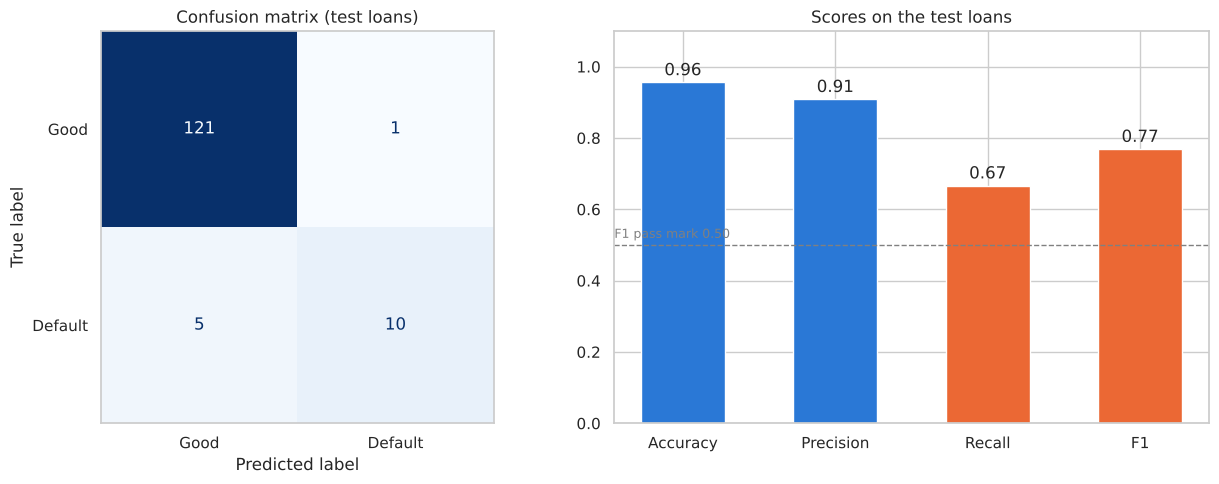

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Good", "Default"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (test loans)")
axes[0].grid(False)

names, values = list(test_scores.keys()), list(test_scores.values())
axes[1].bar(names, values, color=[GOOD, GOOD, BAD, BAD], width=0.55)
for i, v in enumerate(values):
    axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center")
axes[1].axhline(0.5, color="grey", linestyle="--", linewidth=1)
axes[1].text(-0.45, 0.52, "F1 pass mark 0.50", fontsize=9, color="grey", ha="left")
axes[1].set_ylim(0, 1.1)
axes[1].set_title("Scores on the test loans")

plt.tight_layout()
plt.show()

**Result:** the model caught 10 of the 15 defaulters in the test loans (recall 67%) and wrongly flagged only 1 good customer, so 10 of its 11 flags were right (precision 91%). The F1 score is 0.77, well above my 0.50 pass mark, and accuracy is 96%.

One thing to keep in mind: there are only 15 defaulters in the test set, which is small, so I also quote the cross-validation F1 (0.56) as the more careful estimate.

## 9. What drives default?

### Feature importance
A Random Forest can tell us how much each feature helped its trees separate defaulters from good borrowers. The bigger the bar, the more the model relies on that feature.

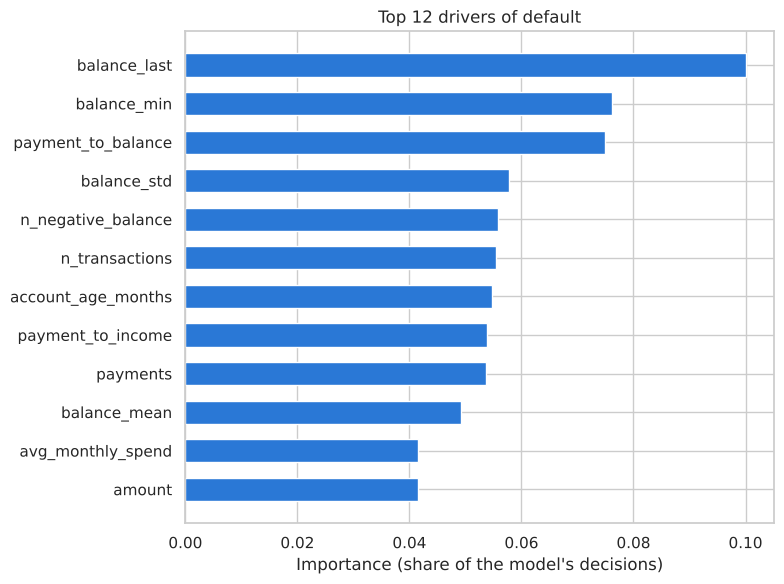

,feature,importance
10,balance_last,0.1001
8,balance_min,0.0762
16,payment_to_balance,0.0749
9,balance_std,0.0578
11,n_negative_balance,0.0557
6,n_transactions,0.0554
4,account_age_months,0.0547
15,payment_to_income,0.0539
2,payments,0.0537
7,balance_mean,0.0493


In [24]:
feature_names = best_model.named_steps["prep"].get_feature_names_out()
imp = pd.DataFrame({"feature": [f.replace("num__", "").replace("cat__", "") for f in feature_names],
                    "importance": best_model.named_steps["model"].feature_importances_})
imp = imp.sort_values("importance")
top = imp.tail(12)

plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["importance"], color=GOOD, height=0.6)
plt.xlabel("Importance (share of the model's decisions)")
plt.title("Top 12 drivers of default")
plt.tight_layout()
plt.show()

imp.sort_values("importance", ascending=False).head(10).round(4)

The most important features are about **account behaviour**: the latest and lowest balance before the loan, the payment compared with the balance, how much the balance jumps around, and overdrafts. District, salary and age matter much less. This matches what I saw in the exploration.

### A simpler model for comparison
Logistic Regression is easier to explain: each feature gets a weight, + means more risk, - means less risk.

In [25]:
lr_model = make_model(LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
print(f"Logistic Regression on the test loans: F1 {f1_score(y_test, lr_pred):.2f}, recall {recall_score(y_test, lr_pred):.0%}, precision {precision_score(y_test, lr_pred):.0%}")
print(f"Random Forest on the test loans:       F1 {test_f1:.2f}, recall {test_scores['Recall']:.0%}, precision {test_scores['Precision']:.0%}\n")

weights = pd.Series(lr_model.named_steps["model"].coef_[0], index=lr_model.named_steps["prep"].get_feature_names_out())
weights.index = weights.index.str.replace("num__", "").str.replace("cat__", "")
weights.reindex(weights.abs().sort_values(ascending=False).index).head(10).round(3)

Logistic Regression on the test loans: F1 0.52, recall 73%, precision 41%
Random Forest on the test loans:       F1 0.77, recall 67%, precision 91%



n_negative_balance        1.947
n_account_users          -1.904
balance_mean             -1.500
balance_std               1.220
card_type_none            1.120
unemployment_96          -0.795
entrepreneurs_per_1000   -0.694
balance_min              -0.630
card_type_classic        -0.627
avg_salary               -0.609
dtype: float64

Logistic Regression catches a few more defaulters but flags many more good customers, so its F1 is lower (0.52 vs 0.77). The Random Forest is the better model, while Logistic Regression's weights are easier to explain to customers or regulators, so a bank could use the forest for decisions and the scorecard for explanations.

## 10. Sanity check

A high score can sometimes come from a mistake (like leakage). To check, I randomly shuffle who defaulted and retrain. If the model learned real patterns, the F1 score should drop close to 0.

In [26]:
rng = np.random.default_rng(RANDOM_STATE)
shuffled = []
for _ in range(3):
    y_shuffled = pd.Series(rng.permutation(y_train.values), index=y_train.index)
    shuffled.append(cross_validate(best_model, X_train, y_shuffled, cv=cv, scoring="f1")["test_score"].mean())
real = cross_validate(best_model, X_train, y_train, cv=cv, scoring="f1")["test_score"].mean()

print(f"F1 with the real answers:     {real:.3f}")
print(f"F1 with shuffled answers:     {np.mean(shuffled):.3f} (+/- {np.std(shuffled):.3f})")

F1 with the real answers:     0.564
F1 with shuffled answers:     0.019 (+/- 0.014)


With shuffled answers the F1 score falls to almost 0, so the model has learned real patterns, not noise.

## 11. Deployment

To make the model usable for new loan applications I:
1. save the trained model to a file
2. write a function that takes an applicant's details and returns their risk
3. score a batch of loans and save the result as a CSV (can be opened in Excel or Power BI)

My rule: only use it if the test F1 score is at least 0.50.

In [27]:
import joblib

joblib.dump(best_model, "loan_default_model.joblib")
print(f"Model saved: loan_default_model.joblib ({os.path.getsize('loan_default_model.joblib') / 1e6:.1f} MB)")
print(f"Test F1 {test_f1:.3f} vs pass mark 0.50 ->", "PASS" if test_f1 >= 0.50 else "FAIL")

Model saved: loan_default_model.joblib (1.9 MB)
Test F1 0.769 vs pass mark 0.50 -> PASS


### Scoring one new applicant
The applicant gives the loan details and their account history. Anything not provided is filled with a typical (median) value. I then turn the probability into three risk bands:
- **Low** (under 30%) → approve
- **Medium** (30–60%) → manual review
- **High** (60% and above) → decline or refer to a credit officer

In [28]:
DEFAULTS = X_train[numeric_features].median().to_dict()
DEFAULTS.update({"frequency": "monthly", "card_type": "none"})
DISTRICT_STATS = district.set_index("district_name")
LOW_CUT, HIGH_CUT = 0.30, 0.60

def prepare_application(app):
    row = {**DEFAULTS, **{k: v for k, v in app.items() if k != "district_name"}}
    if "district_name" in app:
        d = DISTRICT_STATS.loc[app["district_name"]]
        row.update(avg_salary=d.avg_salary, unemployment_96=d.unemployment_96, entrepreneurs_per_1000=d.entrepreneurs_per_1000,
                   urban_ratio=d.urban_ratio, crime_rate_per_1000=d.crimes_96 / d.inhabitants * 1000)
    row["payments"] = row["amount"] / row["duration"]
    row["payment_to_income"] = row["payments"] / max(row["avg_monthly_income"], 1)
    row["payment_to_balance"] = row["payments"] / max(row["balance_mean"], 1)
    return pd.DataFrame([row])[numeric_features + categorical_features]

def score_application(app, model=best_model):
    p = float(model.predict_proba(prepare_application(app))[0, 1])
    band = "High" if p >= HIGH_CUT else "Medium" if p >= LOW_CUT else "Low"
    action = {"High": "Decline or refer to credit officer", "Medium": "Refer for manual review", "Low": "Approve"}[band]
    return {"default_probability": round(p, 3), "risk_band": band, "suggested_action": action}

# two example customers asking for the same loan
healthy = {"amount": 100000, "duration": 24, "balance_mean": 45000, "balance_min": 5000, "balance_last": 40000,
           "avg_monthly_income": 25000, "n_negative_balance": 0, "n_penalty_interest": 0, "district_name": "Hl.m. Praha"}
stretched = {**healthy, "balance_mean": 15000, "balance_min": -500, "balance_last": 8000, "n_negative_balance": 3}
print("Healthy account:  ", score_application(healthy))
print("Stretched account:", score_application(stretched))

# save everything the demo app needs in one file (used by Loan_Risk_Demo.ipynb)
joblib.dump({"model": best_model, "defaults": DEFAULTS, "numeric_features": numeric_features,
             "categorical_features": categorical_features, "low_cut": LOW_CUT, "high_cut": HIGH_CUT,
             "test_f1": round(test_f1, 3),
             "district_stats": DISTRICT_STATS[["avg_salary", "unemployment_96", "entrepreneurs_per_1000",
                                               "urban_ratio", "crimes_96", "inhabitants"]]}, "loan_risk_app.joblib")
print("\nSaved loan_risk_app.joblib for the demo app")

Healthy account:   {'default_probability': 0.02, 'risk_band': 'Low', 'suggested_action': 'Approve'}


Stretched account: {'default_probability': 0.668, 'risk_band': 'High', 'suggested_action': 'Decline or refer to credit officer'}



Saved loan_risk_app.joblib for the demo app


### Batch scoring: all test loans

In [29]:
scored = df.loc[X_test.index, ["loan_id", "account_id", "amount", "duration", "balance_min"]].copy()
scored["default_probability"] = best_model.predict_proba(X_test)[:, 1].round(3)
scored["risk_band"] = pd.cut(scored["default_probability"], [-0.01, LOW_CUT, HIGH_CUT, 1.01],
                             labels=["Low", "Medium", "High"], right=False)
scored["actual_default"] = y_test.values
scored.to_csv("scored_applications.csv", index=False)   # for Excel / Power BI

scored.groupby("risk_band", observed=True).agg(loans=("loan_id", "count"),
                                               actual_default_rate=("actual_default", "mean")).round(3)

,loans,actual_default_rate
risk_band,,
Low,112,0.009
Medium,16,0.312
High,9,1.000


The bands work well: most of the High band really defaulted, and almost none of the Low band did.

## 12. Web app demo

I used **Gradio** to turn the model into a small web page where you can type in an applicant and get their risk. (For the presentation I use the separate notebook **Loan_Risk_Demo.ipynb**, which opens a nicer version of this app without rerunning everything.)

In [30]:
%pip install -q gradio

In [31]:
import gradio as gr

def predict_ui(district_name, amount, duration, balance_mean, balance_min, balance_last, avg_monthly_income,
               n_negative_balance, n_penalty_interest, client_age, card_type):
    result = score_application({"district_name": district_name, "amount": amount, "duration": int(duration),
                                "balance_mean": balance_mean, "balance_min": balance_min, "balance_last": balance_last,
                                "avg_monthly_income": avg_monthly_income, "n_negative_balance": n_negative_balance,
                                "n_penalty_interest": n_penalty_interest, "client_age": client_age, "card_type": card_type})
    return f"{result['default_probability']:.1%}", result["risk_band"], result["suggested_action"]

demo = gr.Interface(
    fn=predict_ui,
    inputs=[
        gr.Dropdown(sorted(district["district_name"]), value="Hl.m. Praha", label="District"),
        gr.Number(value=100000, label="Loan amount (CZK)"),
        gr.Dropdown([12, 24, 36, 48, 60], value=24, label="Duration (months)"),
        gr.Number(value=45000, label="Average account balance (CZK)"),
        gr.Number(value=5000, label="Lowest account balance (CZK)"),
        gr.Number(value=40000, label="Latest account balance (CZK)"),
        gr.Number(value=25000, label="Average monthly income (CZK)"),
        gr.Slider(0, 20, value=0, step=1, label="Times overdrawn"),
        gr.Slider(0, 10, value=0, step=1, label="Penalty-interest charges"),
        gr.Slider(18, 80, value=40, step=1, label="Client age"),
        gr.Dropdown(["none", "junior", "classic", "gold"], value="none", label="Card held"),
    ],
    outputs=[gr.Textbox(label="Default probability"), gr.Textbox(label="Risk band"), gr.Textbox(label="Suggested action")],
    title="Loan Default Risk Scorer",
    flagging_mode="never",
)

In [ ]:
demo.launch(share=True)   # opens the app below and gives a public gradio.live link

Other systems can also get a score automatically through the app's **API** (no typing needed). For example:

In [ ]:
from gradio_client import Client
api = Client(demo.local_url)
print(api.predict("Hl.m. Praha", 100000, 24, 15000, -500, 8000, 25000, 3, 0, 40, "none", api_name="/predict_ui"))

## 13. Scalability and adaptability

**Scalability** – can it handle a lot of loans? I time how long it takes to score 100,000 and 200,000 loans, and how long it takes to summarise all 1 million transactions.

In [32]:
for n in [100_000, 200_000]:
    batch = X_test.sample(n, replace=True, random_state=RANDOM_STATE)
    start = time.perf_counter()
    best_model.predict_proba(batch)
    secs = time.perf_counter() - start
    print(f"Scored {n:,} loans in {secs:.2f} seconds ({n / secs:,.0f} loans per second)")

start = time.perf_counter()
trans.groupby("account_id").agg(n=("trans_id", "size"), avg=("balance", "mean"), low=("balance", "min"))
print(f"Summarised {len(trans):,} transactions in {time.perf_counter() - start:.2f} seconds")

Scored 100,000 loans in 0.77 seconds (129,603 loans per second)


Scored 200,000 loans in 1.38 seconds (144,516 loans per second)
Summarised 1,056,320 transactions in 0.05 seconds


**Adaptability** – does it still work on newer loans? I train only on loans from 1993–1996 and test on loans from 1997–1998. This is how a model is really used: built on the past, used on the future.

In [33]:
from sklearn.base import clone

past = df["loan_year"] <= 1996
recent = df["loan_year"] >= 1997
new_model = clone(best_model).fit(X[past], y[past])   # same settings, retrained on the older loans only
oot_pred = new_model.predict(X[recent])
oot_f1 = f1_score(y[recent], oot_pred)
print(f"Trained on {past.sum()} loans (1993-96), tested on {recent.sum()} later loans (1997-98)")
print(f"On the later loans: F1 {oot_f1:.2f}, caught {recall_score(y[recent], oot_pred):.0%} of defaulters ({y[recent].sum()} defaulters)")

Trained on 328 loans (1993-96), tested on 354 later loans (1997-98)
On the later loans: F1 0.65, caught 73% of defaulters (30 defaulters)


It still scores well on later years, and retraining is just one line, so the model can be updated easily when new data comes in.

## 14. Monitoring

Once a model is in use, it needs regular checks. I would check three things every month:

| What | How | Alert if |
|---|---|---|
| Are applicants changing? | PSI (Population Stability Index) for each feature | above 0.25 (0.10–0.25 = watch) |
| Is the model still good? | F1 score | below 0.50 |
| Is the default rate shifting? | actual default rate vs before | more than 5 percentage points |

Below I compare the newer loans (1997–98) with the older ones (1993–96).

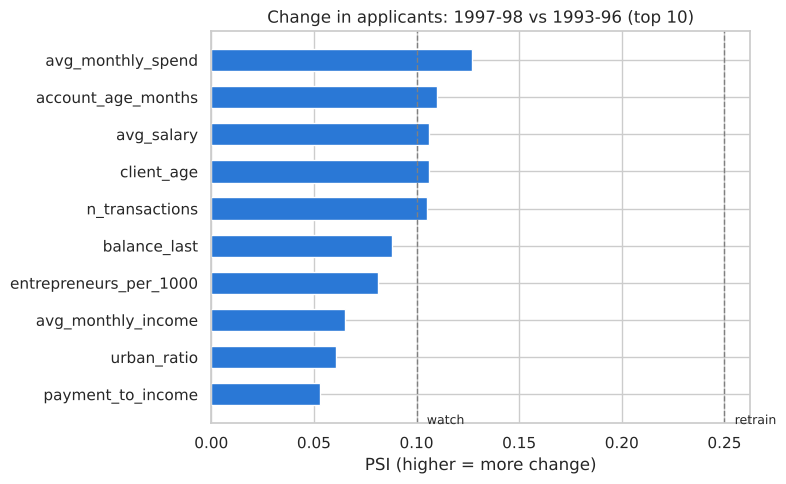

,feature,psi,status
14,avg_monthly_spend,0.127,Watch
4,account_age_months,0.110,Watch
17,avg_salary,0.106,Watch
3,client_age,0.106,Watch
6,n_transactions,0.105,Watch
10,balance_last,0.088,Stable
19,entrepreneurs_per_1000,0.081,Stable
13,avg_monthly_income,0.065,Stable


In [34]:
def psi(old, new, bins=10):
    # Population Stability Index: how different is the new data from the old data?
    if old.dtype == object or old.dtype.name in ("str", "string", "category"):
        old_pct = old.value_counts(normalize=True)
        new_pct = new.value_counts(normalize=True)
        cats = old_pct.index.union(new_pct.index)
        old_pct, new_pct = old_pct.reindex(cats, fill_value=0), new_pct.reindex(cats, fill_value=0)
    else:
        edges = np.unique(np.quantile(old, np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        old_pct = pd.cut(old, edges).value_counts(normalize=True, sort=False)
        new_pct = pd.cut(new, edges).value_counts(normalize=True, sort=False)
    old_pct, new_pct = old_pct.clip(lower=1e-4), new_pct.clip(lower=1e-4)
    return float(((new_pct - old_pct) * np.log(new_pct / old_pct)).sum())

drift = pd.DataFrame({"feature": numeric_features + categorical_features})
drift["psi"] = [round(psi(X.loc[past, f], X.loc[recent, f]), 3) for f in drift["feature"]]
drift["status"] = pd.cut(drift["psi"], [-1, 0.10, 0.25, np.inf], labels=["Stable", "Watch", "Retrain"])
drift = drift.sort_values("psi", ascending=False)

top10 = drift.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top10["feature"], top10["psi"], color=GOOD, height=0.6)
for x, label in [(0.10, "watch"), (0.25, "retrain")]:
    plt.axvline(x, color="grey", linestyle="--", linewidth=1)
    plt.text(x + 0.005, -0.8, label, fontsize=9)
plt.xlabel("PSI (higher = more change)")
plt.title("Change in applicants: 1997-98 vs 1993-96 (top 10)")
plt.tight_layout()
plt.show()
drift.head(8)

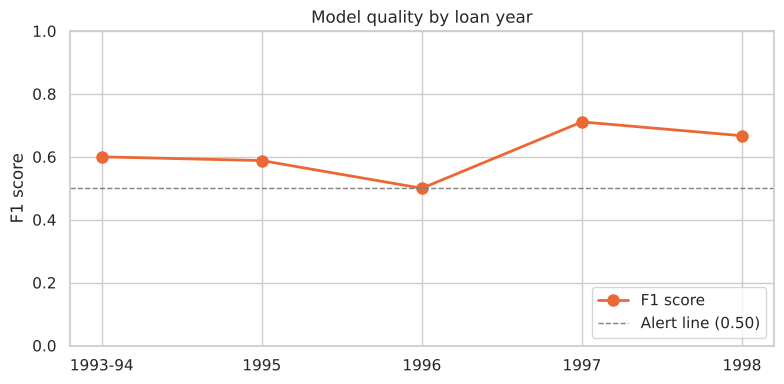

,period,loans,defaulters,recall,f1
0,1993-94,121,18,0.500,0.600
1,1995,90,12,0.417,0.588
2,1996,117,16,0.375,0.500
3,1997,196,26,0.615,0.711
4,1998,158,4,1.000,0.667


In [35]:
# model quality for each loan year (using cross-validated predictions so every loan gets a fair score)
oof = cross_val_predict(best_model, X, y, cv=cv)
by_year = pd.DataFrame({"year": df["loan_year"].clip(lower=1994), "actual": y.values, "predicted": oof})

rows = []
for year, grp in by_year.groupby("year"):
    rows.append([("1993-94" if year == 1994 else str(year)), len(grp), grp["actual"].sum(),
                 round(recall_score(grp["actual"], grp["predicted"]), 3), round(f1_score(grp["actual"], grp["predicted"]), 3)])
perf_by_period = pd.DataFrame(rows, columns=["period", "loans", "defaulters", "recall", "f1"])

plt.figure(figsize=(8, 4))
plt.plot(perf_by_period["period"], perf_by_period["f1"], marker="o", color=BAD, linewidth=2, markersize=8, label="F1 score")
plt.axhline(0.50, color="grey", linestyle="--", linewidth=1, label="Alert line (0.50)")
plt.ylim(0, 1.0)
plt.ylabel("F1 score")
plt.title("Model quality by loan year")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
perf_by_period

In [36]:
max_psi = drift["psi"].max()
rate_shift = y[recent].mean() - y[past].mean()
print(f"Biggest PSI:          {max_psi:.3f}  ->", "OK" if max_psi < 0.10 else "WATCH" if max_psi < 0.25 else "ALERT")
print(f"Lowest yearly F1:     {perf_by_period['f1'].min():.3f}  ->", "OK" if perf_by_period['f1'].min() >= 0.50 else "ALERT")
print(f"Default-rate shift:   {rate_shift:+.3f}  ->", "OK" if abs(rate_shift) <= 0.05 else "ALERT")

Biggest PSI:          0.127  -> WATCH
Lowest yearly F1:     0.500  -> OK
Default-rate shift:   -0.055  -> ALERT


**My reading:** the F1 score stays at or above 0.50 in every year. A few features are in the "watch" zone, which is normal as customers change over time, and a good reason to retrain regularly.

The default-rate alert is expected: loans from 1998 are only a few months old, so they haven't had time to go bad yet. In real monitoring I would compare loans of the same age.

## 15. Conclusion and recommendations

**How well does the model work?**
- The tuned Random Forest has a test **F1 score of 0.77** (pass mark 0.50) and **0.56** in cross-validation.
- It caught **10 of 15** defaulters in the test loans (recall 67%), and **10 of its 11 flags were right** (precision 91%). Accuracy is 96%.
- It passed the sanity check (shuffled answers drop the F1 to 0.02) and still worked on later years (F1 0.65, 73% of defaulters caught).

**What drives default?**
- Mostly **account behaviour before the loan**: low or unstable balances, overdrafts, penalty interest, and a monthly payment that is large compared with the usual balance.
- Accounts shared by two people were safer (none of them defaulted).
- District, salary, age and card type matter much less.

**Recommendations for the bank**
1. Pilot the model: score every application, with a credit officer reviewing the High-risk ones.
2. Treat overdrafts and low balances before a loan as early warning signs.
3. Add dates to standing orders so this data can be used safely in future.
4. Monitor the model monthly (PSI, F1 score, default rate) and retrain when an alert comes up.
5. Keep gender out of credit decisions and check the results are fair.
6. Use the simple Logistic Regression scorecard to explain decisions to customers.

**Limitations:** the dataset is small (682 loans), old (1990s) and from one bank, so the next step would be to test the approach on newer data.